In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [3]:
DATA_DIR = "../data/chest_xray"

train_dir = os.path.join(DATA_DIR, "train")
val_dir = os.path.join(DATA_DIR, "val")
test_dir = os.path.join(DATA_DIR, "test")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 5


In [4]:
train_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)
val_test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary"
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary"
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)


Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


In [5]:
# Charger MobileNetV2 pré-entraîné
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Geler les couches du modèle pré-entraîné
base_model.trainable = False

# Ajouter une tête de classification personnalisée
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation="relu")(x)
x = Dropout(0.5)(x)
output = Dense(1, activation="sigmoid")(x)

# Créer le modèle final
model_mobilenet = Model(inputs=base_model.input, outputs=output)


In [6]:
model_mobilenet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


In [8]:
history_mobilenet = model_mobilenet.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator
)


Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 65s 379ms/step - accuracy: 0.8917 - loss: 0.2576 - val_accuracy: 0.8750 - val_loss: 0.2740
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 61s 371ms/step - accuracy: 0.9528 - loss: 0.1348 - val_accuracy: 0.8750 - val_loss: 0.2787
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 57s 349ms/step - accuracy: 0.9651 - loss: 0.1036 - val_accuracy: 0.8750 - val_loss: 0.2182
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 56s 345ms/step - accuracy: 0.9678 - loss: 0.0938 - val_accuracy: 0.9375 - val_loss: 0.1627
Epoch 5/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 56s 346ms/step - accuracy: 0.9701 - loss: 0.0862 - val_accuracy: 0.9375 - val_loss: 0.1798


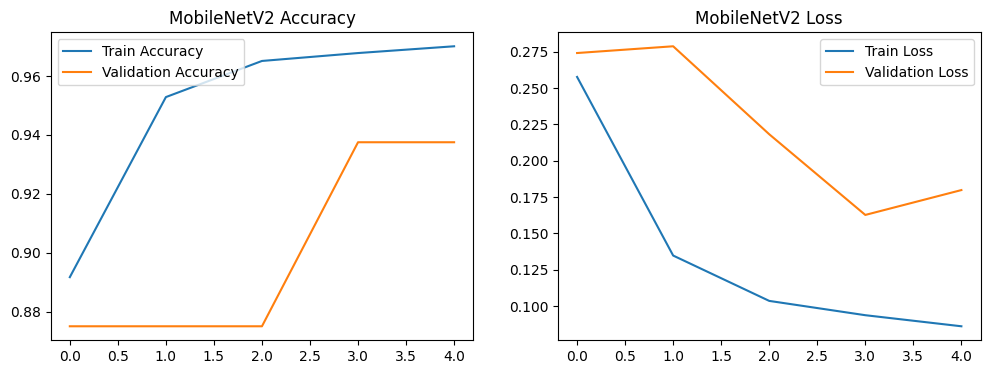

In [9]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history_mobilenet.history["accuracy"], label="Train Accuracy")
plt.plot(history_mobilenet.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.title("MobileNetV2 Accuracy")

plt.subplot(1,2,2)
plt.plot(history_mobilenet.history["loss"], label="Train Loss")
plt.plot(history_mobilenet.history["val_loss"], label="Validation Loss")
plt.legend()
plt.title("MobileNetV2 Loss")

plt.show()


In [10]:
test_loss, test_accuracy = model_mobilenet.evaluate(test_generator)

print("MobileNetV2 Test Accuracy :", test_accuracy)
print("MobileNetV2 Test Loss :", test_loss)


20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 322ms/step - accuracy: 0.8269 - loss: 0.4861
MobileNetV2 Test Accuracy : 0.8269230723381042
MobileNetV2 Test Loss : 0.4860684871673584


In [11]:
import os
os.makedirs("../model", exist_ok=True)

model_mobilenet.save("../model/mobilenetv2_pneumonia_model.keras")


Analyse des performances de MobileNetV2

Le modèle basé sur MobileNetV2 a été évalué sur un ensemble de test indépendant composé de 624 images.
Les résultats obtenus montrent une amélioration notable par rapport au modèle CNN simple, avec une accuracy d’environ 82 %.

Les courbes d’apprentissage indiquent une convergence rapide et une meilleure stabilité des performances, confirmant l’intérêt du transfert d’apprentissage pour l’extraction de caractéristiques pertinentes à partir de radiographies pulmonaires.

Malgré ces améliorations, certaines erreurs subsistent, principalement dues à la complexité du dataset médical et au déséquilibre entre les classes.